<a href="https://colab.research.google.com/github/anosh1314/VaccineTrials_analysis/blob/main/vaccine_trails_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
"""
Phase 3 vaccine trials: pull, extract, analyze (ClinicalTrials.gov API v2)
VERSION 1 - complete script

Colab setup (run once in its own cell):
    !pip install requests pandas matplotlib scipy textstat

Outputs (saved in the working folder):
    vaccine_trials_raw.csv          full extracted table
    vaccine_trials_clean.csv        after cleaning
    summary_by_status.csv           medians, completed vs terminated only
    stats_results.csv               Mann-Whitney tests (all years + 2010 onward)
    why_stopped_coded.csv           terminated trials with reason category
    validation_sample.csv           8 random trials to hand-check criteria counts
    enrollment.png, sites.png, elig_words.png, readability.png

    # Phase 3 Vaccine Trials: Completed vs. Terminated
Exploratory analysis of 1,626 Phase 3 vaccine trial records from ClinicalTrials.gov (independent project).

**Question:** How do terminated trials differ from completed ones in sites, eligibility length, and outcomes?
**Data:** ClinicalTrials.gov API v2, pulled October 2026. Filters: intervention "vaccine", Phase 3, status Completed or Terminated. Three case-study trials are compared against the group medians.
**Main findings:** Terminated trials had longer eligibility text (median 492 vs 326 words) and listed more sites (median 11.5 vs 4). Both held in trials starting 2010 or later. Exploratory Mann-Whitney tests; associations only, not causes.
**Validation:** The script's inclusion/exclusion counts were hand-checked against registry pages. They matched exactly in 3 of 5 random trials and 3 of 3 case studies, but overcount when criteria contain nested sub-items, so item counts are not used for the main conclusions.
**Limitations:** One registry; terminated trials started later than completed ones; results are exploratory.
"""
import os
import re
import time
import datetime
import requests
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu


In [38]:
# ---------------------------------------------------------------- SETTINGS
PULL_FROM_API = True      # True = fresh pull. False = load vaccine_trials_raw.csv
RAW_CSV = "vaccine_trials_raw.csv"

CASE_STUDIES = {
    "NCT07860216": "RSV (BeneWill)",
    "NCT00505453": "Fluviral (GSK)",
    "NCT05973006": "Novavax adolescent",
}
BASE = "https://clinicaltrials.gov/api/v2/studies"
MAX_COMPLETED = 5000      # high on purpose to pull ALL completed trials returned
MAX_TERMINATED = 5000
ALPHA_STRICT = 0.05 / 4   # Bonferroni cutoff for the 4 exploratory tests
SENSITIVITY_FROM_YEAR = 2010
MIN_GROUP_N = 15          # skip a test if either group has fewer records than this



In [39]:
# ---------------------------------------------------------------- PULL DATA
def pull_studies(status, max_records):
    """Phase 3 vaccine trials with a given overall status.
    Record these exact filters in your methods section."""
    params = {
        "query.intr": "vaccine",
        "filter.overallStatus": status,
        "filter.advanced": "AREA[Phase]PHASE3",
        "pageSize": 100,
        "format": "json",
    }
    studies, token = [], None
    while len(studies) < max_records:
        if token:
            params["pageToken"] = token
        r = requests.get(BASE, params=params, timeout=30)
        r.raise_for_status()
        data = r.json()
        studies += data.get("studies", [])
        print(f"  {status}: {len(studies)} records so far")
        token = data.get("nextPageToken")
        if not token:
            break
        time.sleep(0.5)
    return studies[:max_records]


def pull_by_id(nct_id):
    r = requests.get(f"{BASE}/{nct_id}", params={"format": "json"}, timeout=30)
    r.raise_for_status()
    return r.json()



In [40]:
# ---------------------------------------------------------------- EXTRACT
def count_criteria(text):
    """Rough count of inclusion/exclusion items (bullets or numbered lines).
    Validate it against hand counts and report the match rate."""
    if not text:
        return None, None
    parts = re.split(r"exclusion criteria", text, flags=re.I)
    incl = parts[0]
    excl = parts[1] if len(parts) > 1 else ""
    pat = re.compile(r"^\s*(?:[\*\-\u2022]|\d+[\.\)])\s+", re.M)
    return len(pat.findall(incl)), len(pat.findall(excl))


def flesch_kincaid(text):
    """Flesch-Kincaid grade level. Bullet lines are treated as sentences.
    Use for RELATIVE comparison only (criteria lists are not normal prose)."""
    if not text:
        return None
    text = re.sub(r"\n+", ". ", text)
    try:
        import textstat
        return textstat.flesch_kincaid_grade(text)
    except ImportError:
        pass
    sentences = max(1, len(re.findall(r"[.!?]+", text)))
    words = re.findall(r"[A-Za-z']+", text)
    if not words:
        return None
    syll = sum(max(1, len(re.findall(r"[aeiouy]+", w.lower()))) for w in words)
    return 0.39 * (len(words) / sentences) + 11.8 * (syll / len(words)) - 15.59


def flatten(study):
    """One nested API record -> one flat row."""
    p = study.get("protocolSection", {})
    ident = p.get("identificationModule", {})
    status = p.get("statusModule", {})
    design = p.get("designModule", {})
    elig = p.get("eligibilityModule", {})
    outc = p.get("outcomesModule", {})
    loc = p.get("contactsLocationsModule", {})
    arms = p.get("armsInterventionsModule", {})
    spons = p.get("sponsorCollaboratorsModule", {})

    elig_text = elig.get("eligibilityCriteria")
    n_incl, n_excl = count_criteria(elig_text)
    locations = loc.get("locations", []) or []

    return {
        "nct_id": ident.get("nctId"),
        "sponsor": spons.get("leadSponsor", {}).get("name"),
        "sponsor_class": spons.get("leadSponsor", {}).get("class"),
        "status": status.get("overallStatus"),
        "start_date": status.get("startDateStruct", {}).get("date"),
        "last_update": status.get("lastUpdatePostDateStruct", {}).get("date"),
        "why_stopped": status.get("whyStopped"),
        "enrollment": design.get("enrollmentInfo", {}).get("count"),
        "enrollment_type": design.get("enrollmentInfo", {}).get("type"),  # ACTUAL / ESTIMATED
        "allocation": design.get("designInfo", {}).get("allocation"),
        "masking": design.get("designInfo", {}).get("maskingInfo", {}).get("masking"),
        "n_arms": len(arms.get("armGroups", []) or []),
        "n_sites": len(locations),
        "n_countries": len({l.get("country") for l in locations if l.get("country")}),
        "min_age": elig.get("minimumAge"),
        "max_age": elig.get("maximumAge"),
        "healthy_volunteers": elig.get("healthyVolunteers"),
        "n_inclusion": n_incl,
        "n_exclusion": n_excl,
        "elig_words": len(elig_text.split()) if elig_text else None,
        "elig_fk_grade": flesch_kincaid(elig_text),
        "n_primary_outcomes": len(outc.get("primaryOutcomes", []) or []),
        "n_secondary_outcomes": len(outc.get("secondaryOutcomes", []) or []),
        "has_results": study.get("hasResults", False),
    }


def build_dataset():
    """Fresh pull from the API, or reload the frozen CSV."""
    if not PULL_FROM_API:
        if not os.path.exists(RAW_CSV):
            raise FileNotFoundError(
                f"{RAW_CSV} not found. Upload it to Colab, or set PULL_FROM_API = True.")
        print(f"Loading saved data from {RAW_CSV} (no API calls).")
        return pd.read_csv(RAW_CSV)

    print("Pulling from ClinicalTrials.gov API (this can take several minutes)...")
    rows = []
    rows += [flatten(s) for s in pull_studies("COMPLETED", MAX_COMPLETED)]
    rows += [flatten(s) for s in pull_studies("TERMINATED", MAX_TERMINATED)]
    df = pd.DataFrame(rows).drop_duplicates("nct_id")

    have = set(df["nct_id"])
    extra = [flatten(pull_by_id(i)) for i in CASE_STUDIES if i not in have]
    if extra:
        df = pd.concat([df, pd.DataFrame(extra)], ignore_index=True)

    df["is_case_study"] = df["nct_id"].isin(CASE_STUDIES)
    df.to_csv(RAW_CSV, index=False)

    with open("data_pull_info.txt", "w") as f:
        f.write(f"Pulled: {datetime.datetime.now():%Y-%m-%d %H:%M}\n")
        f.write("Source: ClinicalTrials.gov API v2\n")
        f.write('Filters: query.intr="vaccine"; filter.advanced=AREA[Phase]PHASE3; '
                "filter.overallStatus=COMPLETED or TERMINATED\n")
        f.write(f"Case studies added by NCT ID: {', '.join(CASE_STUDIES)}\n")
        f.write(f"Records: {len(df)}\n")
        f.write(df["status"].value_counts().to_string() + "\n")
    print("Saved vaccine_trials_raw.csv and data_pull_info.txt. DOWNLOAD THEM NOW.")
    return df


In [41]:

# ---------------------------------------------------------------- CLEAN
def clean(df):

    df = df.copy()
    print(f"\nStart: {len(df)} trials")
    df["is_case_study"] = df["nct_id"].isin(CASE_STUDIES)
    df["enrollment"] = pd.to_numeric(df["enrollment"], errors="coerce")
    print(f"Enrollment missing/non-numeric: {df['enrollment'].isna().sum()} (left missing)")

    # FIX: dates arrive as YYYY, YYYY-MM or YYYY-MM-DD. Read the first 4 characters.
    df["start_year"] = pd.to_numeric(df["start_date"].astype(str).str[:4], errors="coerce")
    print(f"Start year missing: {df['start_year'].isna().sum()} (left missing)")
    print("Start-date string lengths (expect a mix of 4, 7 and 10):")
    print(df["start_date"].dropna().astype(str).str.len().value_counts().to_string())
    print(f"Start year range: {df['start_year'].min():.0f} to {df['start_year'].max():.0f}")

    df["pct_fields_blank"] = df.isna().mean(axis=1) * 100
    df.to_csv("vaccine_trials_clean.csv", index=False)

    print("\nTrials per status (report these counts in your methods):")
    print(df["status"].value_counts())
    print("\nEnrollment type by status (ACTUAL vs ESTIMATED):")
    print(pd.crosstab(df["status"], df["enrollment_type"].fillna("missing")))
    print("\nStart year by status, comparison groups only:")
    grp = df[df["status"].isin(["COMPLETED", "TERMINATED"]) & ~df["is_case_study"]]
    print(grp.groupby("status")["start_year"].describe().round(1))
    return df


In [42]:
# ---------------------------------------------------------------- DESCRIBE
def comparison_groups(df):
    """Completed vs terminated, case studies excluded.
    (The RECRUITING RSV trial is a case study only, never a group.)"""
    return df[df["status"].isin(["COMPLETED", "TERMINATED"]) & ~df["is_case_study"]]


def describe(df):
    cols = ["enrollment", "n_sites", "n_countries", "n_inclusion", "n_exclusion",
            "elig_words", "elig_fk_grade", "n_primary_outcomes", "n_secondary_outcomes"]
    d = comparison_groups(df)
    summary = d.groupby("status")[cols].median().round(1)
    print("\nMedians by status (completed vs terminated only, descriptive):")
    print(summary)
    summary.to_csv("summary_by_status.csv")
    print("\nYour case studies:")
    print(df[df["is_case_study"]][["nct_id", "status", "enrollment_type"] + cols]
          .round(1).to_string(index=False))


In [43]:
# ---------------------------------------------------------------- STATS
def run_tests(d, label):
    """Mann-Whitney U with rank-biserial effect size.
    r > 0: COMPLETED values tend to be higher. r < 0: TERMINATED values higher."""
    out = []
    for col in ["n_sites", "n_exclusion", "elig_words", "n_primary_outcomes"]:
        a = d[d.status == "COMPLETED"][col].dropna()
        b = d[d.status == "TERMINATED"][col].dropna()
        if len(a) < MIN_GROUP_N or len(b) < MIN_GROUP_N:
            print(f"  [{label}] {col}: skipped (groups too small: {len(a)} / {len(b)})")
            continue
        u, p = mannwhitneyu(a, b, alternative="two-sided")
        r = 2 * u / (len(a) * len(b)) - 1
        out.append({
            "sample": label, "variable": col,
            "n_completed": len(a), "n_terminated": len(b),
            "median_completed": a.median(), "median_terminated": b.median(),
            "U": u, "p": p, "effect_r": round(r, 2),
            "passes_strict_cutoff": p < ALPHA_STRICT,
        })
    return out


def stats_section(df):
    d = comparison_groups(df)
    results = run_tests(d, "all years")
    # Sensitivity: era could explain both site count and criteria length
    d_recent = d[d["start_year"] >= SENSITIVITY_FROM_YEAR]
    results += run_tests(d_recent, f"start year {SENSITIVITY_FROM_YEAR}+")
    res = pd.DataFrame(results)
    res["p"] = res["p"].apply(lambda x: "<0.001" if x < 0.001 else round(x, 3))
    res.to_csv("stats_results.csv", index=False)
    print(f"\nMann-Whitney results (strict cutoff p < {ALPHA_STRICT:.4f}, exploratory):")
    print(res.to_string(index=False))


In [44]:
# ---------------------------------------------------------------- WHY STOPPED
STOP_CATEGORIES = [
    ("Low enrollment / recruitment", ["enrol", "enroll", "recruit", "accrual"]),
    ("Safety", ["safety", "adverse", "toxicity", "death"]),
    ("Efficacy / futility", ["efficacy", "futil", "ineffective", "no benefit"]),
    ("Funding / sponsor / business decision", ["fund", "sponsor", "business", "strategic",
                                              "company", "priority", "portfolio", "decision",
                                              "commercial"]),
    ("Pandemic / external events", ["covid", "pandemic", "epidemic", "outbreak"]),
    ("Regulatory / approval", ["regulat", "approv", "license", "authoriz", "fda", "ema"]),
    ("Supply / logistics", ["supply", "manufactur", "logistic", "vaccine availab"]),
]


def code_reason(text):
    if not isinstance(text, str) or not text.strip():
        return "Not stated"
    t = text.lower()
    for name, keys in STOP_CATEGORIES:
        if any(k in t for k in keys):
            return name
    return "Other"


def why_stopped_section(df):
    t = df[(df["status"] == "TERMINATED") & ~df["is_case_study"]].copy()
    t["reason_category"] = t["why_stopped"].apply(code_reason)
    print("\nWhy terminated trials stopped (keyword-coded, first match wins):")
    print(t["reason_category"].value_counts())
    print("Hand-review every row before quoting a count (open why_stopped_coded.csv).")
    t[["nct_id", "why_stopped", "reason_category"]].to_csv("why_stopped_coded.csv", index=False)



In [45]:
# ---------------------------------------------------------------- VALIDATION
def validation_sample(df):
    """8 random trials. ClinicalTrials.gov."""
    s = comparison_groups(df).sample(10, random_state=42)[
        ["nct_id", "n_inclusion", "n_exclusion"]].copy()
    s["hand_inclusion"] = ""
    s["hand_exclusion"] = ""
    s.to_csv("validation_sample.csv", index=False)
    print("\nSaved validation_sample.csv. Fill the hand_ columns, then score.")
    return s


def verification_log(df):

    check = comparison_groups(df).sample(15, random_state=7)[
        ["nct_id", "status", "enrollment", "n_sites", "n_primary_outcomes",
         "n_secondary_outcomes", "start_date"]].copy()
    for c in ["web_status", "web_enrollment", "web_sites", "web_primary",
              "web_secondary", "web_start"]:
        check[c] = ""
    check.to_csv("verification_log.csv", index=False)
    print("Saved verification_log.csv.")
    return check

# nct_id: (hand inclusion count, hand exclusion count)

HAND_COUNTS = {
    # random validation sample (hand-counted)
    "NCT05045144": (5, 23),
    "NCT02094586": (4, 13),
    "NCT01352793": (1, 5),
    "NCT02545517": (1, 3),
    "NCT04605159": (18, 32),
    # case studies (reported separately)
    "NCT00505453": (2, 9),
    "NCT07860216": (5, 17),
    "NCT05973006": (6, 18),
}

def score_validation(df, hand_counts):
    rows = []
    for nct, (hi, he) in hand_counts.items():
        match = df[df["nct_id"] == nct]
        if match.empty:
            print(f"{nct}: not in df, skipped")
            continue
        r = match.iloc[0]
        rows.append({
            "nct_id": nct,
            "case_study": nct in CASE_STUDIES,
            "script_incl": pd.to_numeric(r["n_inclusion"], errors="coerce"),
            "hand_incl": hi,
            "script_excl": pd.to_numeric(r["n_exclusion"], errors="coerce"),
            "hand_excl": he,
        })
    v = pd.DataFrame(rows)
    v["incl_diff"] = v["script_incl"] - v["hand_incl"]
    v["excl_diff"] = v["script_excl"] - v["hand_excl"]
    v["both_exact"] = (v["incl_diff"] == 0) & (v["excl_diff"] == 0)
    v.to_csv("validation_results.csv", index=False)
    print(v.to_string(index=False))

    def report(sub, label):
        n = len(sub)
        if n == 0:
            return
        print(f"\n{label} (n = {n} trials)")
        print(f"  Inclusion exact match: {(sub.incl_diff == 0).sum()} of {n}")
        print(f"  Exclusion exact match: {(sub.excl_diff == 0).sum()} of {n}")
        print(f"  Both counts exact:     {sub.both_exact.sum()} of {n}")
        within1 = ((sub.incl_diff.abs() <= 1) & (sub.excl_diff.abs() <= 1)).sum()
        print(f"  Both within +/-1:      {within1} of {n}")
        mae = pd.concat([sub.incl_diff.abs(), sub.excl_diff.abs()]).mean()
        print(f"  Mean absolute error:   {mae:.2f} items")

    report(v[~v.case_study], "RANDOM SAMPLE (report this one in the README)")
    report(v[v.case_study], "CASE STUDIES (report separately)")
    return v


In [46]:
# ---------------------------------------------------------------- CHARTS
def chart_box(df, col, title, fname, log=False):
    """Completed vs terminated boxplots; case studies as red dots."""
    d = comparison_groups(df).dropna(subset=[col])
    order = ["COMPLETED", "TERMINATED"]
    groups = [d[d.status == s][col].values for s in order]
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    try:
        ax.boxplot(groups, tick_labels=order)       # matplotlib 3.9+
    except TypeError:
        ax.boxplot(groups, labels=order)            # older matplotlib
    cs = df[df["is_case_study"]].dropna(subset=[col])
    for _, r in cs.iterrows():
        x = 1 if r["status"] == "COMPLETED" else 2 if r["status"] == "TERMINATED" else 2.5
        ax.scatter([x], [r[col]], color="red", zorder=3)
        ax.annotate(CASE_STUDIES[r["nct_id"]], (x, r[col]),
                    fontsize=7, xytext=(6, 3), textcoords="offset points")
    if log:
        ax.set_yscale("log")
    ax.set_title(title)
    ax.set_ylabel(col + (" (log scale)" if log else ""))
    ax.set_xlim(0.5, 3.2)
    fig.tight_layout()
    fig.savefig(fname, dpi=200)
    plt.show()
    plt.close(fig)


Pulling from ClinicalTrials.gov API (this can take several minutes)...
  COMPLETED: 100 records so far
  COMPLETED: 200 records so far
  COMPLETED: 300 records so far
  COMPLETED: 400 records so far
  COMPLETED: 500 records so far
  COMPLETED: 600 records so far
  COMPLETED: 700 records so far
  COMPLETED: 800 records so far
  COMPLETED: 900 records so far
  COMPLETED: 1000 records so far
  COMPLETED: 1100 records so far
  COMPLETED: 1200 records so far
  COMPLETED: 1300 records so far
  COMPLETED: 1400 records so far
  COMPLETED: 1500 records so far
  COMPLETED: 1561 records so far
  TERMINATED: 64 records so far
Saved vaccine_trials_raw.csv and data_pull_info.txt. DOWNLOAD THEM NOW.

Start: 1626 trials
Enrollment missing/non-numeric: 10 (left missing)
Start year missing: 6 (left missing)
Start-date string lengths (expect a mix of 4, 7 and 10):
start_date
10    899
7     721
Start year range: 1977 to 2026

Trials per status (report these counts in your methods):
status
COMPLETED     1

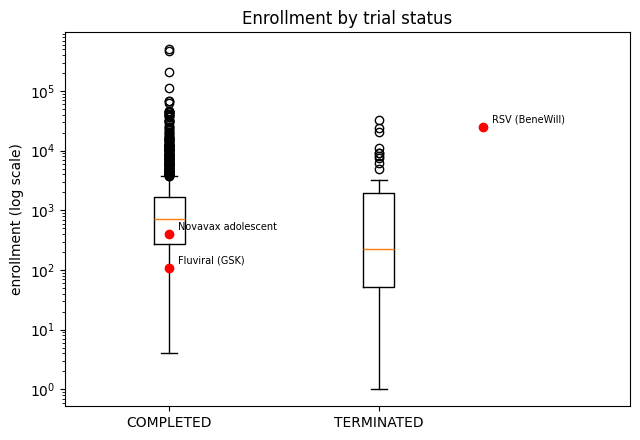

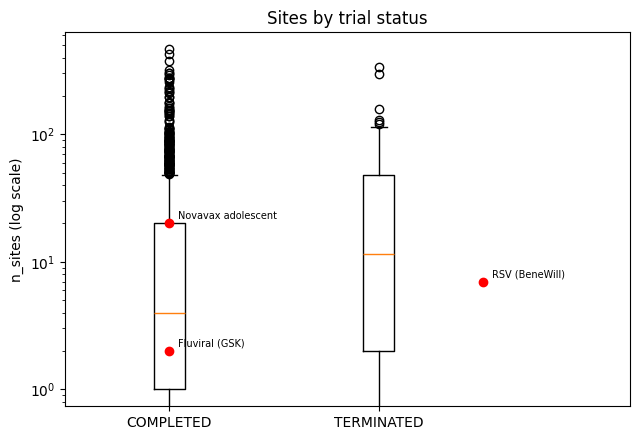

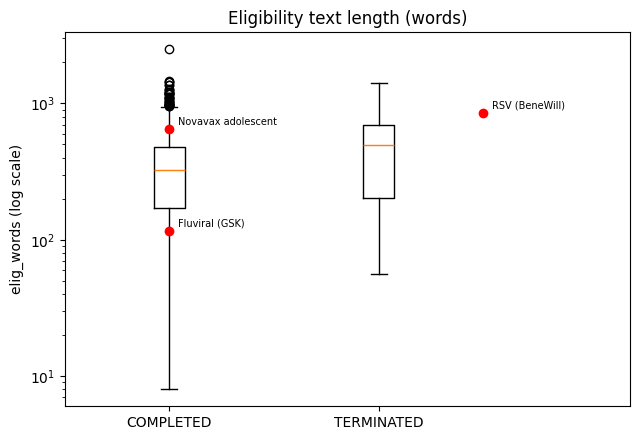

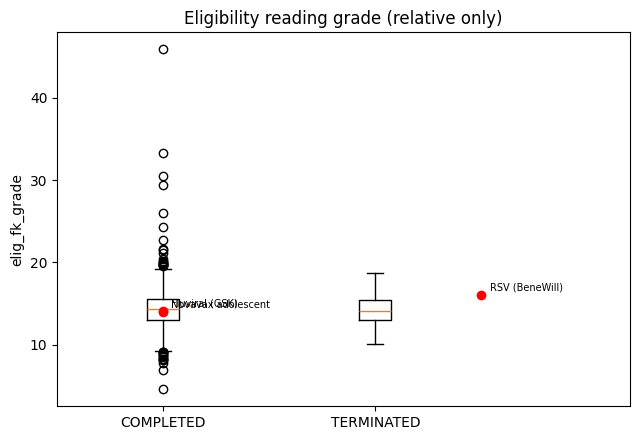


Done. Files saved to the working folder.
Next: fill validation_sample.csv and verification_log.csv by hand,
then run: score_validation(df, HAND_COUNTS)
     nct_id  case_study  script_incl  hand_incl  script_excl  hand_excl  incl_diff  excl_diff  both_exact
NCT05045144       False            8          5           22         23          3         -1       False
NCT02094586       False            4          4           13         13          0          0        True
NCT01352793       False            1          1            5          5          0          0        True
NCT02545517       False            1          1            3          3          0          0        True
NCT04605159       False           18         18           46         32          0         14       False
NCT00505453        True            2          2            9          9          0          0        True
NCT07860216        True            5          5           17         17          0          0        True

In [47]:

# ---------------------------------------------------------------- MAIN
if __name__ == "__main__" or True:   # "or True" lets it run when pasted into Colab
    df = clean(build_dataset())
    describe(df)
    stats_section(df)
    why_stopped_section(df)
    validation_sample(df)
    verification_log(df)
    chart_box(df, "enrollment", "Enrollment by trial status", "enrollment.png", log=True)
    chart_box(df, "n_sites", "Sites by trial status", "sites.png", log=True)
    chart_box(df, "elig_words", "Eligibility text length (words)", "elig_words.png", log=True)
    chart_box(df, "elig_fk_grade", "Eligibility reading grade (relative only)", "readability.png")
    print("\nDone. Files saved to the working folder.")
    print("Next: fill validation_sample.csv and verification_log.csv by hand,")
    print("then run: score_validation(df, HAND_COUNTS)")

    score_validation(df, HAND_COUNTS)

